In [1]:

# Experiment 3: Comparing Machine Learning Algorithms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


In [2]:

# Load the official MNIST dataset

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

# Preserve the original MNIST split
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Number of classes:", len(np.unique(y_train)))


Training data: (60000, 784)
Testing data: (10000, 784)
Number of classes: 10


In [3]:

# Define our machine learning models

models = {
    "kNN (k=3)": KNeighborsClassifier(
        n_neighbors=3,
        metric="euclidean",
        algorithm="brute",
        n_jobs=1
    ),

    "Logistic Regression": LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        C=1.0
    ),

    "SVM (RBF)": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        cache_size=1000
    )
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- kNN (k=3)
- Logistic Regression
- SVM (RBF)


In [4]:

# Step 5: Train and compare all three models

results = []
predictions = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Measure training time
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    # Measure prediction time
    start = time.perf_counter()
    y_pred = model.predict(X_test)
    prediction_time = time.perf_counter() - start

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Save predictions for later analysis
    predictions[name] = y_pred

    # Store results
    results.append({
        "Algorithm": name,
        "Accuracy (%)": accuracy * 100,
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Training time: {train_time:.2f}s")
    print(f"Prediction time: {prediction_time:.2f}s")

comparison_df = pd.DataFrame(results)

print("\nFINAL COMPARISON")
print(comparison_df.to_string(index=False))


Training kNN (k=3)...
Accuracy: 97.05%
Training time: 0.13s
Prediction time: 4.90s

Training Logistic Regression...


/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/jayden/Desktop/MLDM/Semester_1/Introduction_to_Machine_Learning/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:33

Accuracy: 92.61%
Training time: 5.69s
Prediction time: 0.02s

Training SVM (RBF)...
Accuracy: 97.92%
Training time: 139.41s
Prediction time: 26.06s

FINAL COMPARISON
          Algorithm  Accuracy (%)  Training Time (s)  Prediction Time (s)
          kNN (k=3)         97.05           0.127671             4.898876
Logistic Regression         92.61           5.694143             0.020783
          SVM (RBF)         97.92         139.413504            26.063053


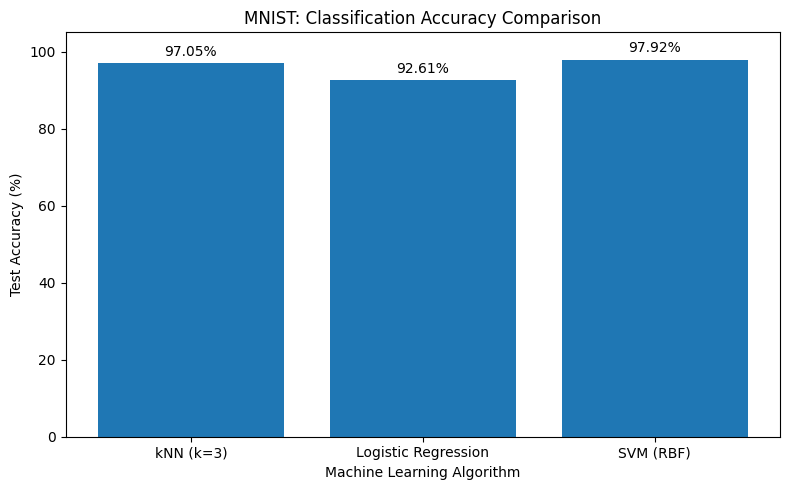

In [5]:

# Step 6: Compare classification accuracy

plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Machine Learning Algorithm")
plt.title("MNIST: Classification Accuracy Comparison")
plt.ylim(0, 105)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("experiment3_accuracy.png", dpi=300)
plt.show()

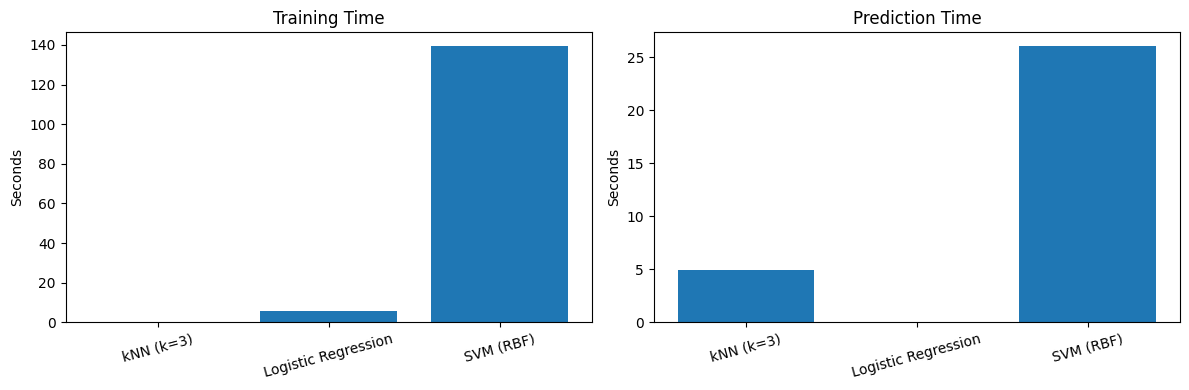

In [6]:

# Step 7: Compare computational performance

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    comparison_df["Algorithm"],
    comparison_df["Training Time (s)"]
)
axes[0].set_title("Training Time")
axes[0].set_ylabel("Seconds")

axes[1].bar(
    comparison_df["Algorithm"],
    comparison_df["Prediction Time (s)"]
)
axes[1].set_title("Prediction Time")
axes[1].set_ylabel("Seconds")

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("experiment3_runtime.png", dpi=300)
plt.show()


In [7]:

# Step 8: Classification reports

for name, y_pred in predictions.items():

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )



kNN (k=3)
              precision    recall  f1-score   support

           0     0.9663    0.9939    0.9799       980
           1     0.9577    0.9982    0.9776      1135
           2     0.9822    0.9651    0.9736      1032
           3     0.9635    0.9663    0.9649      1010
           4     0.9754    0.9674    0.9714       982
           5     0.9663    0.9630    0.9646       892
           6     0.9833    0.9854    0.9844       958
           7     0.9649    0.9640    0.9645      1028
           8     0.9892    0.9384    0.9631       974
           9     0.9603    0.9594    0.9598      1009

    accuracy                         0.9705     10000
   macro avg     0.9709    0.9701    0.9704     10000
weighted avg     0.9707    0.9705    0.9705     10000


Logistic Regression
              precision    recall  f1-score   support

           0     0.9523    0.9776    0.9648       980
           1     0.9627    0.9789    0.9707      1135
           2     0.9291    0.9012    0.9149   

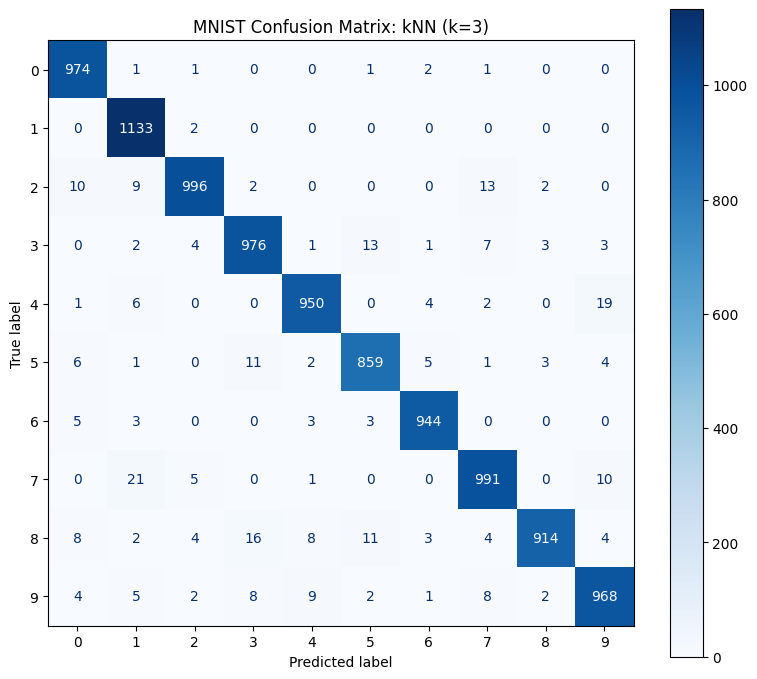

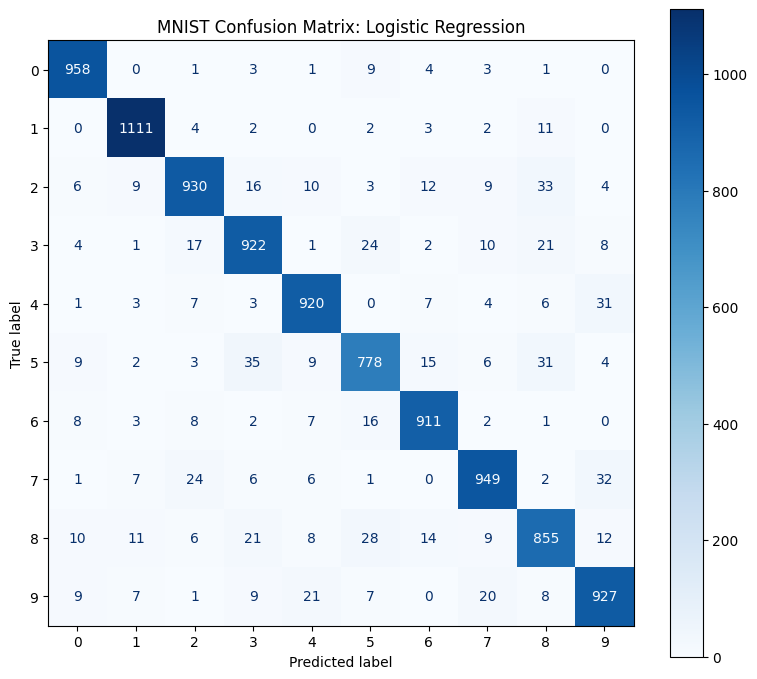

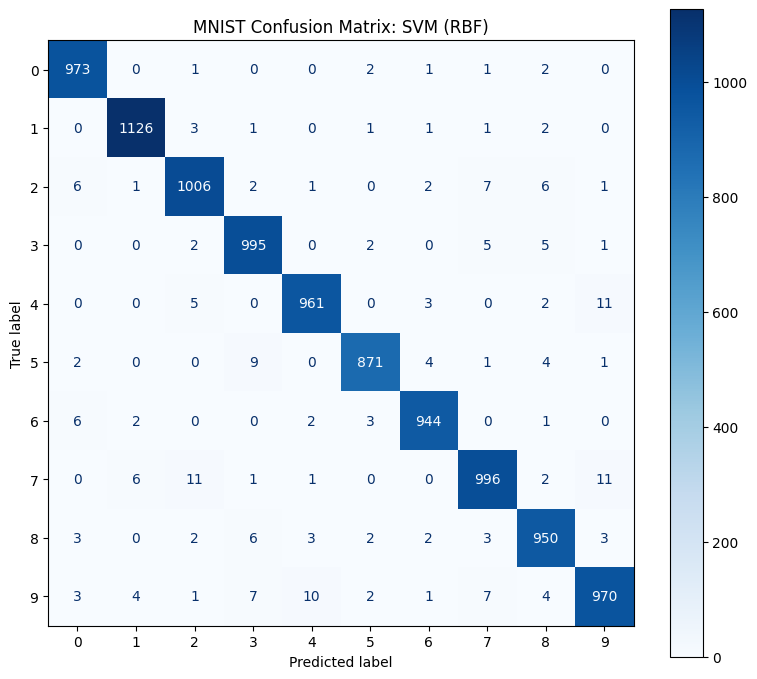

In [8]:

# Step 9: Confusion matrices

for name, y_pred in predictions.items():

    fig, ax = plt.subplots(figsize=(8, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"MNIST Confusion Matrix: {name}")

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("=", "")
    )

    plt.tight_layout()
    plt.savefig(
        f"confusion_{filename}.png",
        dpi=300
    )
    plt.show()


In [9]:

# Step 10: Save results

comparison_df.to_csv(
    "experiment3_results.csv",
    index=False
)

print("Results saved successfully.")


Results saved successfully.
